# Pareja B — Modelo no lineal: Random Forest

## 2.0 Alcance

Este notebook cubre **exclusivamente el eje de la pareja B**:

- implementación y entrenamiento del Modelo 2 (**Random Forest**) bajo *las mismas* particiones que el modelo base de la pareja A;
- búsqueda de hiperparámetros mediante **validación cruzada anidada** (validación interna solo sobre el entrenamiento de cada pliegue);
- extracción de **importancia de variables** y de **reglas de decisión** (árbol pequeño, solo con fines interpretativos).

No incluye curvas ROC comparativas, matrices de confusión comparativas ni la prueba t: eso corresponde a la pareja C. Por eso este notebook **no toca el conjunto de prueba** y deja guardados los resultados por pliegue en el mismo formato que usa la pareja A.

### Protocolo común (acordado en el Hito 1)

| Elemento | Valor |
|---|---|
| Semilla | `random_state=42` |
| Partición train/test | 80 % / 20 %, estratificada |
| Validación externa | `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre `X_train` |
| Métrica principal | recall de la clase falsa (`1`) |
| Métricas complementarias | accuracy, precision (falso), F1 (falso) |

In [1]:
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# --- Constantes IDÉNTICAS a las de la pareja A (no cambiar sin avisar) ---
FEATURES = ['variance', 'skewness', 'kurtosis', 'entropy']
TARGET = 'is_fake'
RANDOM_STATE = 42
PLOTS_DIR = Path('../report/plots')
RESULTS_DIR = Path('../results/pareja_b')
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

blues = plt.get_cmap('Blues')
corals = plt.get_cmap('RdPu')
COLORS = {0: blues(0.72), 1: corals(0.72)}
CLASS_LABELS = {0: 'Genuino (0)', 1: 'Falso (1)'}

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'figure.dpi': 110,
})

# 2.1 Carga de datos y partición (idéntica a la pareja A)

Se usa la **misma** llamada a `train_test_split` (`test_size=0.20`, `stratify=y`, `random_state=42`). Con los mismos argumentos y el mismo orden del archivo, las filas de entrenamiento y prueba son exactamente las de la pareja A, lo que garantiza que la comparación entre modelos sea justa.

El conjunto `X_test` queda apartado: aquí **no se usa**.

In [2]:
data_path = Path('../data/data_banknote_authentication.txt')
if not data_path.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {data_path.resolve()}')

df = pd.read_csv(data_path, header=None, names=FEATURES + [TARGET])
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise').astype(int)

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Train: {len(X_train):,} | Test (sin usar): {len(X_test):,}')
print(f'Proporción de falsos en train: {y_train.mean():.3f}')

Train: 1,097 | Test (sin usar): 275
Proporción de falsos en train: 0.445


# 2.2 Random Forest: teoría breve y decisión sobre el escalado

Un **Random Forest** es un conjunto (*ensemble*) de $B$ árboles de decisión entrenados sobre muestras *bootstrap* del entrenamiento. En cada nodo, cada árbol considera solo un subconjunto aleatorio de `max_features` variables para elegir la mejor partición. La predicción final es el promedio de las probabilidades de los árboles:

$$\hat{P}(y=1\mid x)=\frac{1}{B}\sum_{b=1}^{B}\hat{P}_b(y=1\mid x),\qquad \hat{y}=\mathbb{1}\left[\hat{P}(y=1\mid x)\ge 0.5\right].$$

Cada árbol divide el espacio con cortes de la forma $x_j \le t$, por lo que la frontera resultante es **no lineal y por tramos ortogonales a los ejes**. Promediar muchos árboles decorrelacionados reduce la varianza respecto a un solo árbol.

### ¿Se escala?

**No es necesario.** Los cortes $x_j \le t$ solo dependen del orden de los valores, no de su escala; estandarizar no cambia las particiones posibles. Por eso aquí el *pipeline* no incluye `StandardScaler`. Esto además elimina por construcción cualquier riesgo de *data leakage* por escalado. (Si se quisiera uniformidad con la pareja A, añadirlo no cambiaría los resultados.)

# 2.3 Espacio de hiperparámetros

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `n_estimators` | 100, 300 | Número de árboles $B$. Más árboles estabilizan la predicción, con rendimientos decrecientes. |
| `max_depth` | 3, 5, 8, `None` | Profundidad máxima. Limita la complejidad de cada árbol (sobreajuste vs. subajuste). |
| `min_samples_leaf` | 1, 3, 5 | Mínimo de observaciones por hoja. Valores altos suavizan la frontera. |
| `max_features` | `'sqrt'`, `None` | Variables consideradas por corte. `'sqrt'` (=2 de 4) decorrelaciona árboles; `None` usa las 4. |

Son $2\times4\times3\times2=48$ combinaciones. Se elige un espacio moderado porque el dataset es pequeño (4 variables) y la meta es documentar un ajuste reproducible, no exprimir centésimas.

### Criterio de selección (validación interna)

El criterio sigue la métrica principal del proyecto: **mayor recall medio de la clase falsa**. Como en este dataset muchas combinaciones empatan en recall (≈1.0), se desempata con **mayor F1 de la clase falsa** y, si persiste el empate, con el **modelo más simple** (menos árboles, menor profundidad). Así la elección no depende del orden en que aparecen las combinaciones.

In [3]:
PARAM_GRID = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [1, 3, 5],
    'max_features': ['sqrt', None],
}

INNER_SCORING = {
    'recall_fake': 'recall',   # pos_label=1 por defecto (clase falsa)
    'f1_fake': 'f1',
}


def select_best(cv_results_):
    # Elige el índice ganador: máx. recall -> máx. F1 -> modelo más simple.
    res = pd.DataFrame(cv_results_)
    res['depth_num'] = res['param_max_depth'].apply(lambda d: np.inf if d is None else d)
    res['recall_r'] = res['mean_test_recall_fake'].round(10)
    res['f1_r'] = res['mean_test_f1_fake'].round(10)
    order = res.sort_values(
        ['recall_r', 'f1_r', 'param_n_estimators', 'depth_num'],
        ascending=[False, False, True, True],
    )
    return int(order.index[0])


def make_search(inner_seed=RANDOM_STATE):
    # GridSearchCV con validación interna estratificada de 3 pliegues.
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=inner_seed)
    return GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        param_grid=PARAM_GRID,
        scoring=INNER_SCORING,
        refit=select_best,
        cv=inner_cv,
        n_jobs=-1,
    )

# 2.4 Validación cruzada anidada (sin tocar el test)

## Estructura

- **Bucle externo** (5 pliegues estratificados, idéntico al de la pareja A): estima el desempeño que se reportará y se comparará con la regresión logística.
- **Bucle interno** (3 pliegues estratificados *dentro del entrenamiento de cada pliegue externo*): elige los hiperparámetros.

El pliegue externo de validación **nunca participa** en la elección de hiperparámetros. Si el ajuste se hiciera sobre los mismos pliegues que se reportan, el resultado quedaría optimista (fuga por selección de modelo).

Se recorre el bucle externo manualmente para poder guardar, por pliegue: las métricas, los hiperparámetros elegidos, las probabilidades fuera de muestra y la importancia de variables. Los pliegues salen del mismo `StratifiedKFold(5, shuffle=True, random_state=42)` aplicado sobre el mismo `X_train` que usó la pareja A.

In [4]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_rows, oof_rows, importance_rows = [], [], []

for fold, (idx_tr, idx_val) in enumerate(outer_cv.split(X_train, y_train), start=1):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

    search = make_search()
    search.fit(X_tr, y_tr)                  # el ajuste usa SOLO el entrenamiento del pliegue
    best_model = search.best_estimator_

    pred = best_model.predict(X_val)
    proba = best_model.predict_proba(X_val)[:, 1]

    fold_rows.append({
        'fold': fold,
        'accuracy': accuracy_score(y_val, pred),
        'precision_fake': precision_score(y_val, pred, pos_label=1, zero_division=0),
        'recall_fake': recall_score(y_val, pred, pos_label=1, zero_division=0),
        'f1_fake': f1_score(y_val, pred, pos_label=1, zero_division=0),
        **{f'best_{k}': v for k, v in search.best_params_.items()},
    })
    oof_rows.append(pd.DataFrame({
        'fold': fold, 'index': X_val.index, 'y_true': y_val.to_numpy(),
        'y_pred': pred, 'proba_fake': proba,
    }))
    importance_rows.append(pd.Series(best_model.feature_importances_, index=FEATURES, name=fold))
    print(f'Pliegue {fold}: recall={fold_rows[-1]["recall_fake"]:.4f} '
          f'f1={fold_rows[-1]["f1_fake"]:.4f} | mejores: {search.best_params_}')

fold_scores_rf = pd.DataFrame(fold_rows).set_index('fold')
oof_predictions = pd.concat(oof_rows, ignore_index=True)
fold_importances = pd.DataFrame(importance_rows)

Pliegue 1: recall=1.0000 f1=0.9899 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
Pliegue 2: recall=1.0000 f1=1.0000 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Pliegue 3: recall=0.9898 f1=0.9700 | mejores: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
Pliegue 4: recall=1.0000 f1=1.0000 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Pliegue 5: recall=0.9897 f1=0.9796 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


# 2.5 Resultados por pliegue y resumen

La tabla por pliegue tiene **las mismas columnas de métricas** (`accuracy`, `precision_fake`, `recall_fake`, `f1_fake`) y el mismo índice `fold` que la pareja A, de modo que la pareja C pueda emparejar pliegue a pliegue para la prueba t. Las columnas `best_*` documentan los hiperparámetros elegidos en cada pliegue.

In [5]:
metric_names = ['accuracy', 'precision_fake', 'recall_fake', 'f1_fake']

summary_rf = pd.DataFrame({
    'metric': metric_names,
    'mean': [fold_scores_rf[m].mean() for m in metric_names],
    'std': [fold_scores_rf[m].std(ddof=1) for m in metric_names],
})
summary_rf['result'] = summary_rf.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)

print('Random Forest — validación cruzada externa (media ± desviación estándar):')
display(summary_rf[['metric', 'result']])
print('Resultados por pliegue:')
display(fold_scores_rf.round(4))

Random Forest — validación cruzada externa (media ± desviación estándar):


,metric,result
0,accuracy,0.9890 ± 0.0119
1,precision_fake,0.9801 ± 0.0209
2,recall_fake,0.9959 ± 0.0056
3,f1_fake,0.9879 ± 0.0131


Resultados por pliegue:


,accuracy,precision_fake,recall_fake,f1_fake,best_max_depth,best_max_features,best_min_samples_leaf,best_n_estimators
fold,,,,,,,,
1,0.9909,0.9800,1.0000,0.9899,8,sqrt,1,300
2,1.0000,1.0000,1.0000,1.0000,8,sqrt,1,100
3,0.9726,0.9510,0.9898,0.9700,5,sqrt,1,300
4,1.0000,1.0000,1.0000,1.0000,8,sqrt,1,100
5,0.9817,0.9697,0.9897,0.9796,8,sqrt,1,300


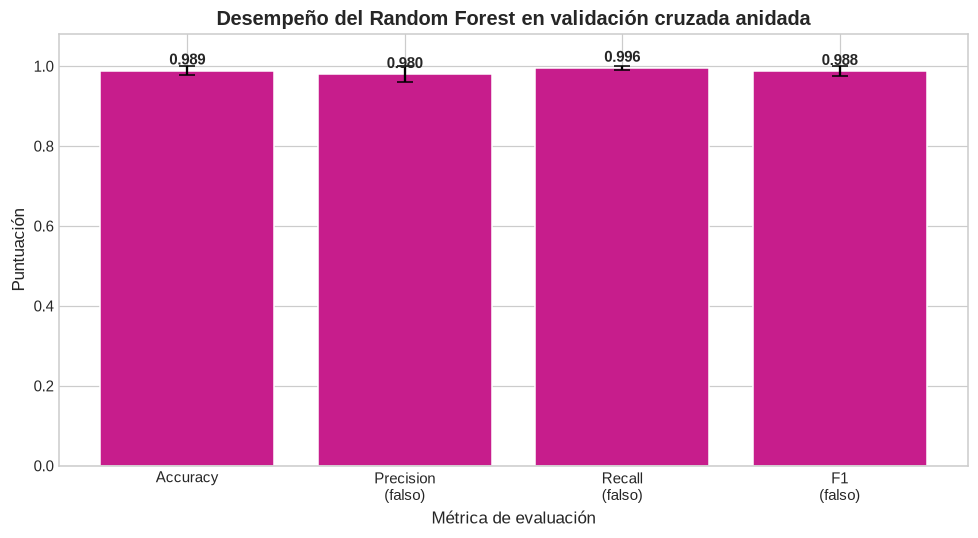

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
metric_labels = {
    'accuracy': 'Accuracy',
    'precision_fake': 'Precision\n(falso)',
    'recall_fake': 'Recall\n(falso)',
    'f1_fake': 'F1\n(falso)',
}
x = np.arange(len(metric_names))
bars = ax.bar(x, summary_rf['mean'], yerr=summary_rf['std'], capsize=5,
              color=corals(0.68), edgecolor='white')
ax.set_xticks(x, [metric_labels[m] for m in metric_names])
ax.set_xlabel('Métrica de evaluación')
ax.set_ylabel('Puntuación')
ax.set_ylim(0, 1.08)
ax.set_title('Desempeño del Random Forest en validación cruzada anidada')
for bar, mean in zip(bars, summary_rf['mean']):
    ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.015, f'{mean:.3f}',
            ha='center', fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '08_rf_metricas_validacion_cruzada.png', dpi=300, bbox_inches='tight')
plt.show()

# 2.6 Hiperparámetros elegidos y estabilidad del ajuste

Si los cinco pliegues eligen configuraciones parecidas, el ajuste es estable. Si cambian mucho, significa que varias configuraciones rinden prácticamente igual en este dataset (algo esperable con 4 variables y clases bien separables) y la elección concreta importa poco.

In [7]:
best_cols = [c for c in fold_scores_rf.columns if c.startswith('best_')]
display(fold_scores_rf[best_cols])

print('Frecuencia de cada valor elegido (sobre los 5 pliegues):')
for col in best_cols:
    print(f'  {col}: {fold_scores_rf[col].astype(str).value_counts().to_dict()}')

,best_max_depth,best_max_features,best_min_samples_leaf,best_n_estimators
fold,,,,
1,8,sqrt,1,300
2,8,sqrt,1,100
3,5,sqrt,1,300
4,8,sqrt,1,100
5,8,sqrt,1,300


Frecuencia de cada valor elegido (sobre los 5 pliegues):
  best_max_depth: {'8': 4, '5': 1}
  best_max_features: {'sqrt': 5}
  best_min_samples_leaf: {'1': 5}
  best_n_estimators: {'300': 3, '100': 2}


# 2.7 Modelo final e importancia de variables

## Ajuste final

Igual que en la pareja A, tras estimar el desempeño con el bucle externo se ajusta **una última instancia sobre todo `X_train`**, repitiendo la búsqueda interna sobre ese conjunto completo. Esta instancia es la que se entregará a la pareja C para la evaluación en `X_test`.

## Importancia de variables

Se usa la **importancia por impureza** (*mean decrease in impurity*): cuánto reduce cada variable, en promedio, la impureza de Gini en los cortes donde participa, normalizada para sumar 1. Se reporta la del modelo final y la media ± desviación entre los 5 modelos de pliegue (como medida de estabilidad).

> Precaución de interpretación: la importancia por impureza se calcula con datos de entrenamiento y puede repartirse entre variables correlacionadas (aquí, `skewness` y `kurtosis` tienen correlación ≈ −0.79). Indica qué usa el modelo, no una relación causal.

In [8]:
final_search = make_search()
final_search.fit(X_train, y_train)
rf_final = final_search.best_estimator_

print('Hiperparámetros del modelo final (búsqueda interna sobre todo X_train):')
print(final_search.best_params_)

final_importance = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
importance_table = pd.DataFrame({
    'final': final_importance,
    'cv_mean': fold_importances.mean().reindex(final_importance.index),
    'cv_std': fold_importances.std(ddof=1).reindex(final_importance.index),
})
display(importance_table.round(4))

Hiperparámetros del modelo final (búsqueda interna sobre todo X_train):
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,final,cv_mean,cv_std
variance,0.5592,0.5644,0.0184
skewness,0.2321,0.2353,0.0133
kurtosis,0.1528,0.1437,0.0116
entropy,0.0559,0.0566,0.0041


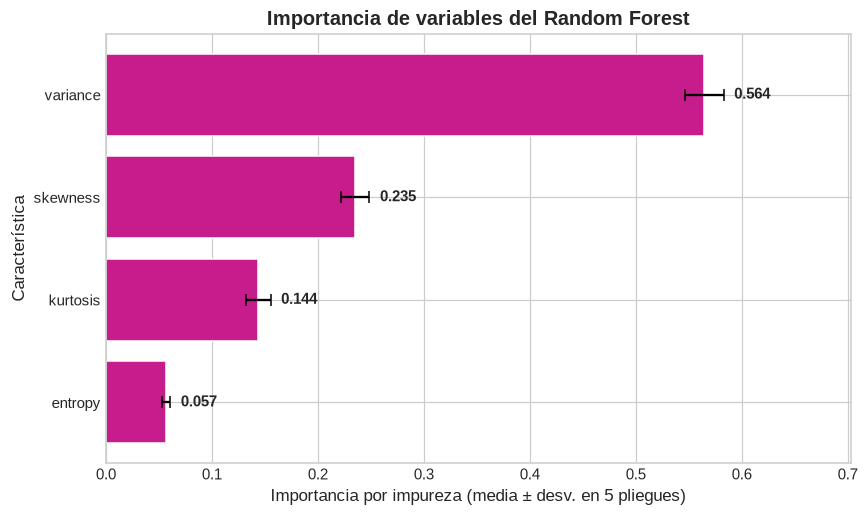

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
order = importance_table.index[::-1]
ax.barh(order, importance_table.loc[order, 'cv_mean'],
        xerr=importance_table.loc[order, 'cv_std'], capsize=4,
        color=corals(0.68), edgecolor='white')
for i, feat in enumerate(order):
    ax.text(importance_table.loc[feat, 'cv_mean'] + importance_table.loc[feat, 'cv_std'] + 0.01,
            i, f"{importance_table.loc[feat, 'cv_mean']:.3f}", va='center', fontweight='bold')
ax.set_xlabel('Importancia por impureza (media ± desv. en 5 pliegues)')
ax.set_ylabel('Característica')
ax.set_title('Importancia de variables del Random Forest')
ax.set_xlim(0, importance_table['cv_mean'].max() + importance_table['cv_std'].max() + 0.12)
plt.tight_layout()
fig.savefig(PLOTS_DIR / '09_rf_importancia_variables.png', dpi=300, bbox_inches='tight')
plt.show()

# 2.8 Reglas de decisión: árbol pequeño interpretable

Un bosque de cientos de árboles no se puede leer. Para ilustrar **qué tipo de reglas** aprende el modelo, se ajusta un único `DecisionTreeClassifier` de profundidad 3 sobre `X_train`. 

Este árbol es **solo explicativo**: no forma parte de la comparación estadística ni se evalúa con el test. Cada hoja corresponde a una conjunción de cortes del tipo $x_j \le t$, que se puede leer como una regla *si–entonces*.

|--- variance <= 0.77
|   |--- skewness <= 5.16
|   |   |--- variance <= 0.32
|   |   |   |--- weights: [20.00, 393.00] class: 1
|   |   |--- variance >  0.32
|   |   |   |--- weights: [22.00, 29.00] class: 1
|   |--- skewness >  5.16
|   |   |--- variance <= -3.43
|   |   |   |--- weights: [1.00, 31.00] class: 1
|   |   |--- variance >  -3.43
|   |   |   |--- weights: [96.00, 1.00] class: 0
|--- variance >  0.77
|   |--- kurtosis <= -4.46
|   |   |--- variance <= 3.30
|   |   |   |--- weights: [0.00, 16.00] class: 1
|   |   |--- variance >  3.30
|   |   |   |--- weights: [8.00, 0.00] class: 0
|   |--- kurtosis >  -4.46
|   |   |--- variance <= 1.74
|   |   |   |--- weights: [80.00, 16.00] class: 0
|   |   |--- variance >  1.74
|   |   |   |--- weights: [382.00, 2.00] class: 0



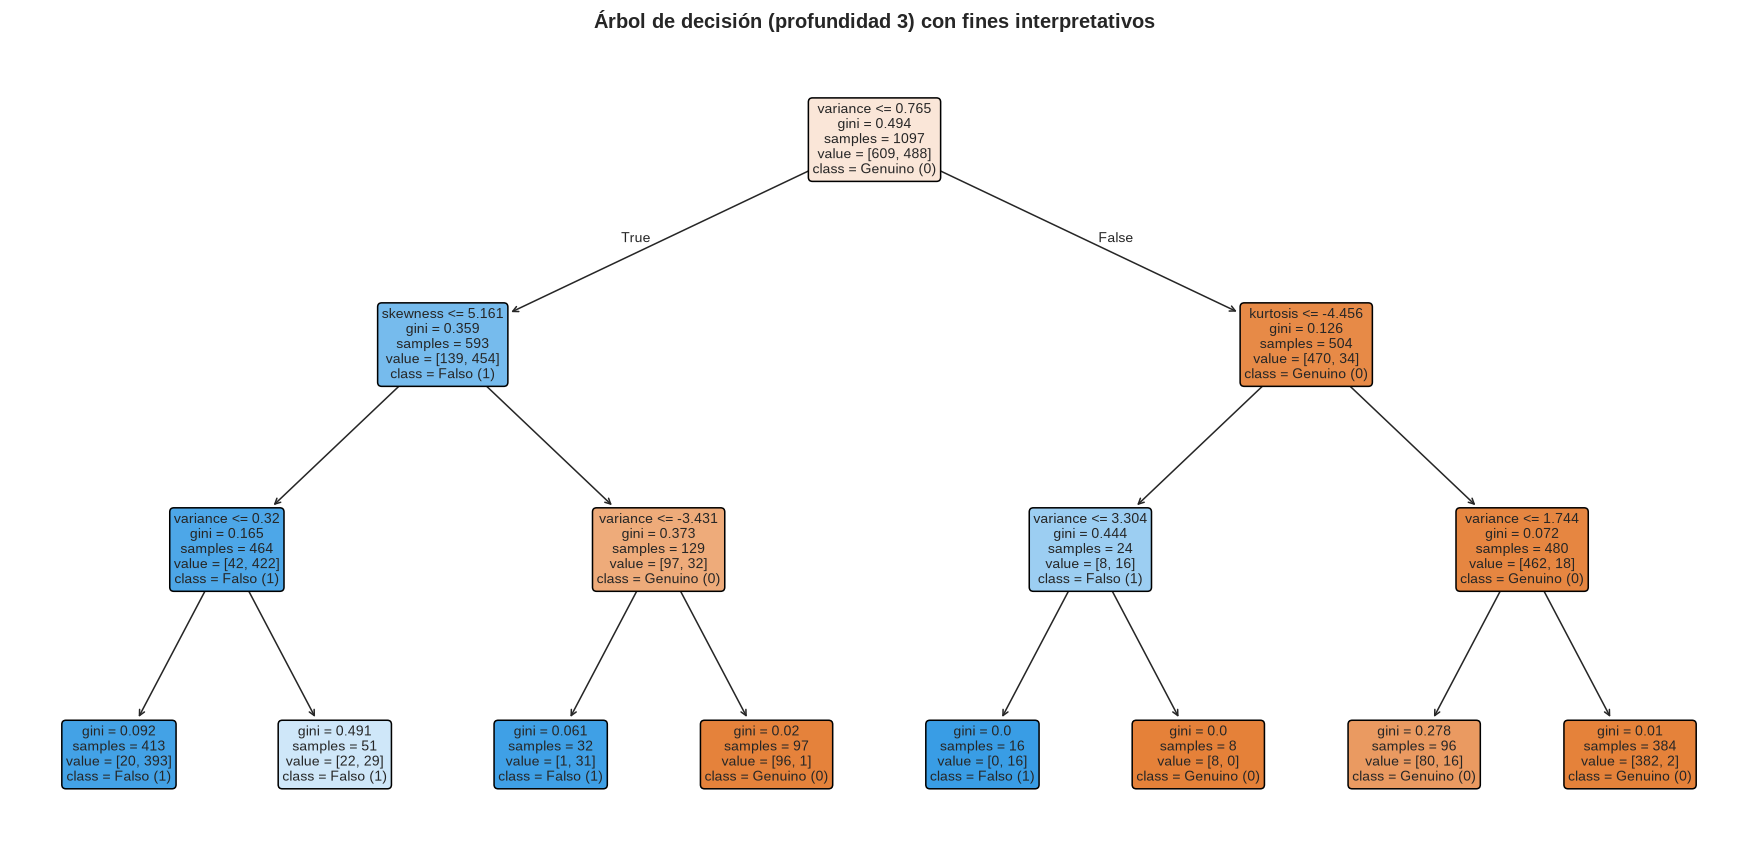

In [10]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

rules_text = export_text(tree, feature_names=FEATURES, show_weights=True)
print(rules_text)
(RESULTS_DIR / '07_reglas_arbol_decision.txt').write_text(rules_text, encoding='utf-8')

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree, feature_names=FEATURES, class_names=[CLASS_LABELS[0], CLASS_LABELS[1]],
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=9, ax=ax)
ax.set_title('Árbol de decisión (profundidad 3) con fines interpretativos')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '10_arbol_decision_reglas.png', dpi=300, bbox_inches='tight')
plt.show()

# 2.9 Exportación de resultados para la pareja C

Se guardan, en `../results/pareja_b/`:

| Archivo | Contenido |
|---|---|
| `01_rf_resumen_cv.csv` | Media y desviación de cada métrica |
| `02_rf_mediciones_por_pliegue.csv` | Métricas e hiperparámetros por pliegue (para la prueba t emparejada) |
| `03_rf_predicciones_fuera_de_muestra.csv` | Probabilidad de falso y predicción de cada observación de `X_train` cuando estuvo en validación |
| `04_rf_importancia_variables.csv` | Importancia final y por pliegue |
| `05_rf_hiperparametros_finales.json` | Hiperparámetros del modelo final |
| `06_modelo_rf_final.joblib` | Modelo final ajustado sobre todo `X_train` (sin haber visto `X_test`) |

In [11]:
import json

summary_rf.to_csv(RESULTS_DIR / '01_rf_resumen_cv.csv', index=False)
fold_scores_rf.to_csv(RESULTS_DIR / '02_rf_mediciones_por_pliegue.csv')
oof_predictions.to_csv(RESULTS_DIR / '03_rf_predicciones_fuera_de_muestra.csv', index=False)
importance_table.to_csv(RESULTS_DIR / '04_rf_importancia_variables.csv')
(RESULTS_DIR / '05_rf_hiperparametros_finales.json').write_text(
    json.dumps(final_search.best_params_, indent=2, default=str), encoding='utf-8')
joblib.dump(rf_final, RESULTS_DIR / '06_modelo_rf_final.joblib')

print('Archivos guardados en', RESULTS_DIR.resolve())
for p in sorted(RESULTS_DIR.iterdir()):
    print(' -', p.name)

Archivos guardados en /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_02/results/pareja_b
 - 01_rf_resumen_cv.csv
 - 02_rf_mediciones_por_pliegue.csv
 - 03_rf_predicciones_fuera_de_muestra.csv
 - 04_rf_importancia_variables.csv
 - 05_rf_hiperparametros_finales.json
 - 06_modelo_rf_final.joblib
 - 07_reglas_arbol_decision.txt


# 2.10 Conclusiones de la pareja B

## Desempeño

El Random Forest, evaluado con validación cruzada anidada de cinco pliegues estratificados, obtuvo un **recall de la clase falsa de 0.9959 ± 0.0056**, un F1 de 0.9879 ± 0.0131, una precision de 0.9801 ± 0.0209 y una accuracy de 0.9890 ± 0.0119. Las diferencias entre pliegues provienen de muy pocas observaciones: los pliegues 3 y 5 tuvieron aproximadamente un falso negativo cada uno (recall ≈ 0.99), mientras que los pliegues 2 y 4 clasificaron sin ningún error. La desviación estándar baja indica que el desempeño es estable frente a la partición.

## Hiperparámetros

La búsqueda interna fue estable: `max_features='sqrt'` y `min_samples_leaf=1` se eligieron en los cinco pliegues, y `max_depth=8` en cuatro de cinco. Solo `n_estimators` alternó entre 100 y 300. Esto sugiere que, en un problema de solo cuatro variables y clases bien separables, varias configuraciones rinden prácticamente igual y la elección concreta tiene poco efecto. El modelo final (ajustado sobre todo `X_train`) eligió `max_depth=None`, `max_features='sqrt'`, `min_samples_leaf=1` y `n_estimators=300`, compatible con lo observado en los pliegues.

## Variables

`variance` domina la importancia por impureza (≈ 0.56), seguida de `skewness` (≈ 0.23), `kurtosis` (≈ 0.15) y `entropy` (≈ 0.06). La desviación entre pliegues es pequeña (≤ 0.02), por lo que el ranking es estable. Debe interpretarse con cautela: `skewness` y `kurtosis` están correlacionadas (≈ −0.79) y la importancia por impureza puede repartirse entre ellas; además, indica qué variables usa el modelo, no una relación causal.

## Reglas de decisión

El árbol de profundidad 3 divide primero por `variance ≤ 0.77`, coherente con la importancia de esa variable. Cuando `variance > 1.74` y la curtosis no es muy negativa, casi todos los billetes son genuinos (hoja con 382 genuinos y 2 falsos). Es un árbol solo explicativo: no participa en la comparación ni se evalúa con el test.

## Limitaciones

- El dataset contiene 24 filas duplicadas que no se eliminaron (criterio de la pareja A). Si una fila cae en entrenamiento y su copia en validación, la estimación puede ser ligeramente optimista. El efecto es pequeño, pero debe decidirse en conjunto si se mantiene este criterio para ambos modelos.
- Con un rendimiento cercano al 99 %, las diferencias frente al modelo lineal serán pequeñas y la prueba estadística con solo cinco pliegues tiene poca potencia.
